# Fase 2B — Depuración, transformación y validación
Reglas: eliminar duplicados exactos; unificar etiquetas; rechazar fechas inválidas, tecnología desconocida o ausente, tiempos negativos e ID repetido; conservar duraciones ausentes sin imputar; agregar mes y minutos.

Carpeta del proyecto: C:\Users\pamel\OneDrive\Escritorio\Proyecto_UNAB_Notebooks_Repositorio_GitHub\Proyecto_UNAB_F1_F2
Existe src: True
Existe pipeline.py: True

=== DATOS ORIGINALES ===
Cantidad de registros: 161
Cantidad de columnas: 7

Primeros registros:
 ID_registro      Fecha Equipo Tecnologia   Tipo_falla  Tiempo_reparacion_h    Estado
           1 2026-01-09 CEX-18  iTrack II       Sensor                 5.22 Operativo
           2 2026-01-08 CEX-18    CAS-GPS Comunicacion                 5.87 Operativo
           3 2026-03-08 CEX-18  iTrack II Alimentacion                 1.20 Operativo
           4 2026-03-17 CEX-42  iTrack II       Sensor                 5.60 Operativo
           5 2026-03-12 CEX-18   Optalert Alimentacion                 2.94 Operativo

=== RESULTADOS DE LA LIMPIEZA ===
{
  "originales": 161,
  "duplicados_exactos": 1,
  "rechazados": 4,
  "aceptados": 156,
  "tiempos_faltantes_aceptados": 1,
  "motivos": {
    "fecha_invalida": 1,
    "tecnologia_invalida

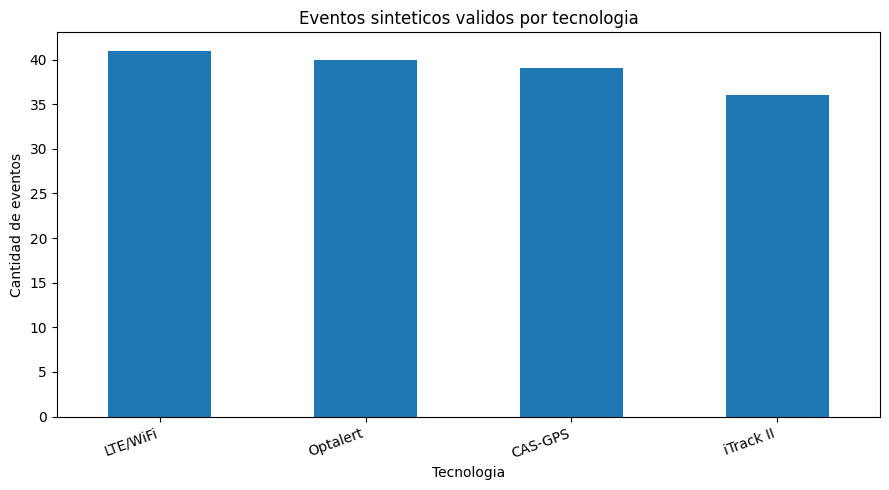


=== RESUMEN FINAL DEL PROCESO ===
Registros originales: 161
Registros limpios: 156
Registros rechazados: 4

Archivos generados:
C:\Users\pamel\OneDrive\Escritorio\Proyecto_UNAB_Notebooks_Repositorio_GitHub\Proyecto_UNAB_F1_F2\datos\registros_limpios.csv
C:\Users\pamel\OneDrive\Escritorio\Proyecto_UNAB_Notebooks_Repositorio_GitHub\Proyecto_UNAB_F1_F2\datos\rechazados.csv
C:\Users\pamel\OneDrive\Escritorio\Proyecto_UNAB_Notebooks_Repositorio_GitHub\Proyecto_UNAB_F1_F2\evidencias\auditoria.json
C:\Users\pamel\OneDrive\Escritorio\Proyecto_UNAB_Notebooks_Repositorio_GitHub\Proyecto_UNAB_F1_F2\figuras\eventos_tecnologia.png

FASE 2B FINALIZADA


In [2]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# FASE 2B - LIMPIEZA, VALIDACION Y ANALISIS DE DATOS
# Proyecto Magister en Ciencia de Datos e IA - UNAB
# ==================================================

# 1. IDENTIFICAR LA CARPETA PRINCIPAL

ruta_proyecto = Path.cwd()

if ruta_proyecto.name == "F2":
    ruta_proyecto = ruta_proyecto.parent

sys.path.insert(0, str(ruta_proyecto))

print("Carpeta del proyecto:", ruta_proyecto)
print("Existe src:", (ruta_proyecto / "src").is_dir())
print(
    "Existe pipeline.py:",
    (ruta_proyecto / "src" / "pipeline.py").is_file()
)

# 2. IMPORTAR FUNCIONES DEL PROYECTO

from src.pipeline import procesar, validar

# 3. CREAR CARPETAS

carpeta_datos = ruta_proyecto / "datos"
carpeta_evidencias = ruta_proyecto / "evidencias"
carpeta_figuras = ruta_proyecto / "figuras"

carpeta_datos.mkdir(exist_ok=True)
carpeta_evidencias.mkdir(exist_ok=True)
carpeta_figuras.mkdir(exist_ok=True)

# 4. CARGAR DATOS ORIGINALES

archivo_original = carpeta_datos / "registros_originales.csv"

original = pd.read_csv(archivo_original)

print("\n=== DATOS ORIGINALES ===")
print("Cantidad de registros:", len(original))
print("Cantidad de columnas:", len(original.columns))
print("\nPrimeros registros:")
print(original.head().to_string(index=False))

# 5. LIMPIAR Y PROCESAR LOS DATOS

limpio, rechazados, auditoria = procesar(original)

# 6. GUARDAR ARCHIVOS PROCESADOS

limpio.to_csv(
    carpeta_datos / "registros_limpios.csv",
    index=False
)

rechazados.to_csv(
    carpeta_datos / "rechazados.csv",
    index=False
)

# 7. GUARDAR AUDITORIA

archivo_auditoria = carpeta_evidencias / "auditoria.json"

archivo_auditoria.write_text(
    json.dumps(
        auditoria,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\n=== RESULTADOS DE LA LIMPIEZA ===")
print(json.dumps(auditoria, indent=2, ensure_ascii=False))

# 8. VALIDAR RESULTADOS

print("\n=== VALIDACION ===")
print(validar(limpio))

# 9. EXPLORACION DE DATOS LIMPIOS

print("\n=== FRECUENCIA POR TECNOLOGIA ===")
print(
    limpio["Tecnologia"]
    .value_counts()
    .to_string()
)

print("\n=== DURACION MEDIA DE REPARACION ===")
print(
    limpio.groupby("Tecnologia")["Tiempo_reparacion_h"]
    .mean()
    .round(2)
    .to_string()
)

# 10. ANALISIS DE EVENTOS POR MES

limpio["Mes"] = pd.to_datetime(
    limpio["Fecha"]
).dt.to_period("M").astype(str)

print("\n=== EVENTOS POR MES ===")
print(
    limpio["Mes"]
    .value_counts()
    .sort_index()
    .to_string()
)

# 11. GENERAR GRAFICO POR TECNOLOGIA

fig, ax = plt.subplots(figsize=(9, 5))

limpio["Tecnologia"].value_counts().plot.bar(ax=ax)

ax.set_title(
    "Eventos sinteticos validos por tecnologia"
)

ax.set_xlabel("Tecnologia")
ax.set_ylabel("Cantidad de eventos")

plt.xticks(rotation=20, ha="right")
fig.tight_layout()

archivo_grafico = carpeta_figuras / "eventos_tecnologia.png"

fig.savefig(
    archivo_grafico,
    dpi=160
)

plt.show()

# 12. RESUMEN FINAL

print("\n=== RESUMEN FINAL DEL PROCESO ===")
print("Registros originales:", len(original))
print("Registros limpios:", len(limpio))
print("Registros rechazados:", len(rechazados))

print("\nArchivos generados:")
print(carpeta_datos / "registros_limpios.csv")
print(carpeta_datos / "rechazados.csv")
print(archivo_auditoria)
print(archivo_grafico)

print("\nFASE 2B FINALIZADA")

## Interpretación y límites
La auditoría cuantifica los registros descartados y documenta sus motivos. Las frecuencias describen exclusivamente el conjunto sintético; no permiten calcular disponibilidad, MTBF, tasas reales de falla ni conclusiones sobre una operación minera. La duración faltante se excluye de promedios mediante el comportamiento documentado de Pandas.